# Sharpe Transformer

A ~4.8M-parameter transformer (10.7M on an A100-class GPU) scores each of 100 long-lived S&P 500 stocks every day. A softmax across the 100 scores gives long-only, fully invested weights, and the model trains directly on the Sharpe ratio after a 5 bps trading cost.

**How to run:** Runtime → Change runtime type → **T4 GPU**, then Runtime → **Run all**. The whole notebook finishes in under 60 minutes; the last cell prints the total.

| Section | What it does |
| --- | --- |
| 1. Setup and config | Installs yfinance, checks the GPU, sets every knob in one `CFG` dict |
| 2. Universe and data | Top 100 current S&P 500 members by market cap with prices back to Jan 3, 2000, cached as Parquet |
| 3. Features | 12 stock + 6 market features per day, plus a leakage unit test |
| 4. Backtester and baselines | Equal-weight, SPY, and 12-1 momentum through one backtester; SPY sanity check |
| 5. Model and loss | Per-stock encoder, softmax portfolio, negative-Sharpe loss; overfit check |
| 6. Walk-forward | 3 test periods × (10-year, 20-year) training windows = 6 runs, each with a time cap |
| 7. Results | Sharpe, return, vol, drawdown, turnover, holdings, gap vs equal-weight with bootstrap CI, accuracy/precision/recall/AUC, cost sensitivity |
| 8. Charts and demo | Equity curves 2020 → today, 10y vs 20y, tomorrow's 100 weights, attention heat map |

Not investment advice. A backtest is not a live result.

## 1. Setup and config

In [ ]:
import os, sys, time, json, math, io, copy, warnings, subprocess
T0 = time.time()
TIMINGS = {}
def tick(stage, t_start):
    TIMINGS[stage] = TIMINGS.get(stage, 0.0) + time.time() - t_start

IN_COLAB = 'google.colab' in sys.modules
SMOKE = os.environ.get('SHARPE_SMOKE') == '1'   # synthetic-data CPU test of the plumbing; never set this for real results
SAVE_TO_DRIVE = False   # True = mount Google Drive and keep the data cache + finished runs there, so a disconnect can resume
REFRESH_DATA = False    # True = ignore the cache and download fresh prices

if IN_COLAB and not SMOKE:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'yfinance'], check=False)

import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from IPython.display import display
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'   # fp16 mixed precision with a gradient scaler (the T4 has no fast bf16)
if DEVICE.type == 'cuda':
    _p = torch.cuda.get_device_properties(0)
    GPU_NAME, GPU_GB = _p.name, _p.total_memory / 1e9
    torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
    print(f'GPU: {GPU_NAME} ({GPU_GB:.0f} GB)')
else:
    GPU_NAME, GPU_GB = 'CPU', 0.0
    if not SMOKE:
        raise RuntimeError('No GPU found. In Colab: Runtime > Change runtime type > T4 GPU, then Run all again.')
    print('CPU smoke test on synthetic data')
print('torch', torch.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

GPU: Tesla T4 (16 GB)
torch 2.11.0+cu130 | pandas 2.2.3 | numpy 2.1.3


In [ ]:
CFG = dict(
    # data
    start='1999-12-01', first_day='2000-01-03', n_stocks=100, max_gap_days=5,
    # features / sequences
    lookback=40, window=63,
    # portfolio
    cost=0.0005, lam=1.0,
    # model (T4 size; A100-class GPUs switch to d_model 384 / FFN 1536 below)
    d_model=256, n_layers=6, n_heads=8, d_ff=1024, dropout=0.1,
    # optimizer
    lr=3e-4, weight_decay=0.05, warmup_steps=20, grad_clip=1.0, patience=5, max_epochs=40,
    # walk-forward
    train_years=[10, 20], val_years=2,
    test_periods=[['2020-01-01', '2021-12-31'], ['2022-01-01', '2023-12-31'], ['2024-01-01', None]],
    time_cap_min={10: 4.0, 20: 8.0},
    # checks and reporting
    overfit_steps=120, overfit_cap_sec=75, bootstrap=1000, block=21, extra_costs=[0.0010, 0.0020], seed=0,
)
if GPU_GB >= 35:                      # A100 / H100: the ~10.7M model trains well within the same caps
    CFG.update(d_model=384, d_ff=1536)
if SMOKE:                             # tiny model and caps so the CPU test takes a few minutes
    CFG.update(d_model=32, n_layers=2, n_heads=4, d_ff=64, time_cap_min={10: 0.2, 20: 0.3},
               overfit_steps=15, overfit_cap_sec=30, bootstrap=100, max_epochs=3)

if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    RUN_DIR = '/content/drive/MyDrive/sharpe-transformer'
elif IN_COLAB:
    RUN_DIR = '/content/sharpe-transformer'
else:
    RUN_DIR = os.path.abspath('sharpe_run_smoke' if SMOKE else 'sharpe_run')
DATA_DIR, RUNS_DIR, FIG_DIR = (f'{RUN_DIR}/{d}' for d in ('data', 'runs', 'figures'))
for d in (DATA_DIR, RUNS_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

try:
    import yaml
    with open(f'{RUN_DIR}/config.yaml', 'w') as f:
        yaml.safe_dump(CFG, f, sort_keys=False)
except ImportError:
    with open(f'{RUN_DIR}/config.json', 'w') as f:
        json.dump(CFG, f, indent=2)
print('Run directory:', RUN_DIR)
print({k: CFG[k] for k in ('d_model', 'n_layers', 'n_heads', 'd_ff', 'cost', 'lam', 'time_cap_min')})

Run directory: /content/sharpe-transformer
{'d_model': 256, 'n_layers': 6, 'n_heads': 8, 'd_ff': 1024, 'cost': 0.0005, 'lam': 1.0, 'time_cap_min': {10: 4.0, 20: 8.0}}


## 2. Universe and data

1. Pull the current S&P 500 list with GICS sectors from Wikipedia.
2. Download daily OHLCV for every member plus `SPY`, `^VIX`, `^TNX`, `^IRX` from yfinance (`auto_adjust=True`, so splits and dividends are folded in).
3. Keep tickers with a price on or before Jan 3, 2000, no gap longer than 5 trading days, and data through today. Rank by current market cap and take the top 100.
4. Freeze `universe.csv` and cache prices as Parquet, so later runs read from disk in seconds.

Picking today's survivors that existed in 2000 inflates absolute returns. That's why the fair benchmark is an equal-weight portfolio of the same 100 stocks.

In [ ]:
FIELDS = ['Open', 'High', 'Low', 'Close', 'Volume']
MARKET = {'SPY': 'spy', '^VIX': 'vix', '^TNX': 'tnx', '^IRX': 'irx'}

def _naive(idx):
    idx = pd.to_datetime(idx)
    return idx.tz_localize(None) if idx.tz is not None else idx

def sp500_table():
    import requests
    url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
    html = requests.get(url, headers={'User-Agent': 'Mozilla/5.0 (sharpe-transformer research notebook)'}, timeout=30).text
    try:
        t = pd.read_html(io.StringIO(html), attrs={'id': 'constituents'})[0]
    except ValueError:
        t = pd.read_html(io.StringIO(html))[0]
    t = t.rename(columns={'Symbol': 'ticker', 'Security': 'name', 'GICS Sector': 'sector'})
    t['ticker'] = t['ticker'].astype(str).str.replace('.', '-', regex=False)   # yfinance writes BRK.B as BRK-B
    return t[['ticker', 'name', 'sector']].drop_duplicates('ticker').reset_index(drop=True)

def yf_fields(tickers, start, chunk=100, tries=5):
    """Batched yfinance download -> {field: wide DataFrame (dates x tickers)}."""
    import yfinance as yf
    out = {f: [] for f in FIELDS}
    for i in range(0, len(tickers), chunk):
        part = list(tickers[i:i + chunk])
        df = None
        for k in range(tries):
            try:
                df = yf.download(part, start=start, auto_adjust=True, progress=False, threads=True, group_by='column')
                if df is not None and len(df):
                    break
            except Exception as e:
                print(f'  download retry {k + 1}: {type(e).__name__}: {e}')
            time.sleep(5 * (k + 1))
        if df is None or not len(df):
            raise RuntimeError(f'yfinance download failed for {part[:5]}...')
        if not isinstance(df.columns, pd.MultiIndex):
            df.columns = pd.MultiIndex.from_product([df.columns, part])
        if 'Close' not in set(df.columns.get_level_values(0)):
            df = df.swaplevel(0, 1, axis=1)
        df.index = _naive(df.index)
        have = set(df.columns.get_level_values(0))
        for f in FIELDS:
            out[f].append(df[f].reindex(columns=part) if f in have else pd.DataFrame(np.nan, index=df.index, columns=part))
        print(f'  downloaded {min(i + chunk, len(tickers))}/{len(tickers)} tickers')
        time.sleep(1)
    return {f: pd.concat(v, axis=1).sort_index().astype(float) for f, v in out.items()}

def longest_gap(s):
    """Longest run of missing values after the first valid price."""
    first = s.first_valid_index()
    if first is None:
        return 10**9
    na = s.loc[first:].isna().to_numpy().astype(int)
    if not na.any():
        return 0
    runs = np.diff(np.flatnonzero(np.diff(np.r_[0, na, 0])))[::2]
    return int(runs.max())

def market_caps(tickers):
    import yfinance as yf
    from concurrent.futures import ThreadPoolExecutor
    def one(t):
        for k in range(3):
            try:
                fi = yf.Ticker(t).fast_info
                try:
                    v = fi['marketCap']
                except Exception:
                    v = fi.market_cap
                if v is not None and np.isfinite(v) and v > 0:
                    return float(v)
            except Exception:
                pass
            time.sleep(1 + 2 * k)
        return np.nan
    with ThreadPoolExecutor(8) as ex:
        return pd.Series(list(ex.map(one, tickers)), index=tickers, dtype=float)

def synthetic_data(n=110, seed=0):
    """SMOKE mode only: random-walk prices with a weak reversal signal, same shapes as the real data."""
    rng = np.random.default_rng(seed)
    cal = pd.bdate_range(CFG['start'], '2026-10-21')
    T = len(cal)
    m = rng.normal(0.0003, 0.011, T)
    beta = rng.uniform(0.6, 1.4, n)
    idio = rng.normal(0.0002, 0.016, (T, n))
    r = m[:, None] * beta + idio
    r[1:] -= 0.08 * idio[:-1]
    close = 50 * np.exp(np.cumsum(r, 0))
    open_ = close * np.exp(rng.normal(0, 0.004, (T, n)))
    high = np.maximum(open_, close) * (1 + np.abs(rng.normal(0, 0.006, (T, n))))
    low = np.minimum(open_, close) * (1 - np.abs(rng.normal(0, 0.006, (T, n))))
    vol = rng.lognormal(15, 0.4, (T, n))
    tick = [f'S{i:03d}' for i in range(n)]
    px = {f: pd.DataFrame(a, index=cal, columns=tick) for f, a in zip(FIELDS, (open_, high, low, close, vol))}
    spy = 100 * np.exp(np.cumsum(m))
    mkt = pd.DataFrame({'spy_open': spy * np.exp(rng.normal(0, 0.002, T)), 'spy_close': spy,
                        'vix': 20 * np.exp(np.cumsum(rng.normal(0, 0.03, T)) * 0.1),
                        'tnx': 3 + np.cumsum(rng.normal(0, 0.03, T)) * 0.05,
                        'irx': np.clip(2 + np.cumsum(rng.normal(0, 0.02, T)) * 0.05, 0, None)}, index=cal)
    sectors = ['Information Technology', 'Health Care', 'Financials', 'Consumer Discretionary', 'Communication Services',
               'Industrials', 'Consumer Staples', 'Energy', 'Utilities', 'Real Estate', 'Materials']
    uni = pd.DataFrame({'ticker': tick, 'name': [f'Synthetic {t}' for t in tick],
                        'sector': [sectors[i % 11] for i in range(n)], 'market_cap': np.sort(rng.lognormal(25, 1, n))[::-1],
                        'first_date': cal[0]})
    return uni.head(CFG['n_stocks']), {f: v[uni.ticker.head(CFG['n_stocks'])] for f, v in px.items()}, mkt

t = time.time()
cache_files = [f'{DATA_DIR}/universe.csv', f'{DATA_DIR}/market.parquet'] + [f'{DATA_DIR}/{f.lower()}.parquet' for f in FIELDS]
if SMOKE:
    universe, PX, MKT = synthetic_data()
elif not REFRESH_DATA and all(os.path.exists(p) for p in cache_files):
    universe = pd.read_csv(f'{DATA_DIR}/universe.csv', parse_dates=['first_date'])
    PX = {f: pd.read_parquet(f'{DATA_DIR}/{f.lower()}.parquet') for f in FIELDS}
    MKT = pd.read_parquet(f'{DATA_DIR}/market.parquet')
    print('Loaded cached data')
else:
    table = sp500_table()
    print(f'{len(table)} current S&P 500 members from Wikipedia')
    allpx = yf_fields(table.ticker.tolist() + list(MARKET), CFG['start'])
    cal = allpx['Close']['SPY'].dropna().index
    first_day = pd.Timestamp(CFG['first_day'])
    close = allpx['Close'].reindex(cal)
    rows = []
    for tk, nm, sec in table.itertuples(index=False):
        if tk not in close:
            continue
        s = close[tk]
        fv = s.first_valid_index()
        ok = fv is not None and fv <= first_day and longest_gap(s) <= CFG['max_gap_days'] and s.iloc[-5:].notna().any()
        if ok:
            rows.append((tk, nm, sec, fv))
    cands = pd.DataFrame(rows, columns=['ticker', 'name', 'sector', 'first_date'])
    print(f'{len(cands)} members have prices back to {first_day.date()} with no long gaps')
    caps = market_caps(cands.ticker.tolist())
    miss = caps[caps.isna()].index.tolist()
    if miss:                                   # one slower retry for any that failed
        time.sleep(5); caps.loc[miss] = market_caps(miss).values
    dollar_vol = (allpx['Close'][cands.ticker] * allpx['Volume'][cands.ticker]).iloc[-63:].mean()
    known = caps.notna()
    if known.sum() >= 0.5 * len(caps):
        ratio = (caps[known] / dollar_vol[known]).median()
        est = caps.fillna(dollar_vol * ratio)
        if (~known).any():
            print(f'Market cap unavailable for {(~known).sum()} tickers; estimated from dollar volume: {list(caps[~known].index)}')
    else:
        print('WARNING: market caps unavailable from yfinance; ranking by 63-day average dollar volume instead')
        est = dollar_vol
    cands['market_cap'] = cands.ticker.map(est)
    universe = cands.sort_values('market_cap', ascending=False).head(CFG['n_stocks']).reset_index(drop=True)
    PX = {f: allpx[f].reindex(cal)[universe.ticker] for f in FIELDS}
    MKT = pd.DataFrame({'spy_open': allpx['Open']['SPY'], 'spy_close': allpx['Close']['SPY'],
                        'vix': allpx['Close']['^VIX'], 'tnx': allpx['Close']['^TNX'], 'irx': allpx['Close']['^IRX']}).reindex(cal)
    universe.to_csv(f'{DATA_DIR}/universe.csv', index=False)
    for f in FIELDS:
        PX[f].to_parquet(f'{DATA_DIR}/{f.lower()}.parquet')
    MKT.to_parquet(f'{DATA_DIR}/market.parquet')
    del allpx
tick('Download and cache', t)
print(f'Universe: {len(universe)} stocks | {PX["Close"].index[0].date()} to {PX["Close"].index[-1].date()} | {time.time() - t:.0f}s')
display(universe.head(15))
print(universe.sector.value_counts().to_string())

503 current S&P 500 members from Wikipedia
  downloaded 100/507 tickers
  downloaded 200/507 tickers
  downloaded 300/507 tickers
  downloaded 400/507 tickers
  downloaded 500/507 tickers
  downloaded 507/507 tickers
343 members have prices back to 2000-01-03 with no long gaps
Universe: 100 stocks | 1999-12-01 to 2026-10-22 | 112s


,ticker,name,sector,first_date,market_cap
0,NVDA,Nvidia,Information Technology,1999-12-01,5.124235e+12
1,AAPL,Apple Inc.,Information Technology,1999-12-01,5.081985e+12
2,MSFT,Microsoft,Information Technology,1999-12-01,3.869303e+12
3,AMZN,Amazon,Consumer Discretionary,1999-12-01,2.700677e+12
4,BRK-B,Berkshire Hathaway,Financials,1999-12-01,1.170904e+12
5,LLY,Lilly (Eli),Health Care,1999-12-01,1.165230e+12
6,MU,Micron Technology,Information Technology,1999-12-01,9.690527e+11
7,WMT,Walmart,Consumer Staples,1999-12-01,9.609354e+11
8,JPM,JPMorgan Chase,Financials,1999-12-01,8.937156e+11
9,AMD,Advanced Micro Devices,Information Technology,1999-12-01,8.291830e+11


sector
Information Technology    20
Financials                18
Health Care               16
Industrials               16
Consumer Discretionary     8
Consumer Staples           7
Energy                     4
Materials                  3
Communication Services     3
Utilities                  3
Real Estate                2


### Calendar and returns

Everything is aligned on SPY's trading days. Market context is forward-filled by at most one day.

The return a set of weights earns follows the plan's timing: features use data through the close on day *t*, trades happen at the open on *t+1*, and the position is held to the open on *t+2*. So the label for day *t* is `open[t+2] / open[t+1] − 1`, and the model never acts on a price it couldn't have seen.

In [ ]:
t = time.time()
TICKERS = universe.ticker.tolist(); N = len(TICKERS)
DATES = MKT['spy_close'].dropna().index
O, H, L, C, V = (PX[f].reindex(DATES)[TICKERS] for f in FIELDS)
C = C.ffill(limit=5)
O = O.where(O > 0).fillna(C.shift(1)).ffill(limit=5)
H = H.where(H > 0).fillna(C); L = L.where(L > 0).fillna(C)
V = V.fillna(0.0)
MK = MKT.reindex(DATES).copy()
MK[['vix', 'tnx', 'irx']] = MK[['vix', 'tnx', 'irx']].ffill(limit=1)
MK['spy_open'] = MK.spy_open.where(MK.spy_open > 0).fillna(MK.spy_close.shift(1))
T = len(DATES)

irx = MK.irx.ffill().fillna(0.0)
if irx.median() > 25:      # guard against an old x10 quote convention
    irx = irx / 10
RF = (irx / 100 / 252).to_numpy()                   # daily T-bill rate

op = O.to_numpy()
FWD = np.full((T, N), np.nan); FWD[:-2] = op[2:] / op[1:-1] - 1
n_wild = int(np.nansum(np.abs(FWD) > 0.75))
FWD = np.clip(FWD, -0.75, 3.0)
FWD0 = np.nan_to_num(FWD)                            # a missing open counts as a flat day
spo = MK.spy_open.to_numpy()
FWD_SPY0 = np.zeros(T); FWD_SPY0[:-2] = np.nan_to_num(spo[2:] / spo[1:-1] - 1)
LAST_EVAL = T - 3                                    # last decision day whose next open-to-open return is known

SECTORS = sorted(universe.sector.unique())
SECTOR_IDS = universe.sector.map({s: i for i, s in enumerate(SECTORS)}).to_numpy()
tick('Features', t)
print(f'{T} trading days, {N} stocks, {len(SECTORS)} sectors | open-to-open returns beyond ±75% clipped: {n_wild}')
print(f'Risk-free (3-month T-bill) annualized: mean {RF.mean() * 252:.2%}, latest {RF[-1] * 252:.2%}')

6764 trading days, 100 stocks, 11 sectors | open-to-open returns beyond ±75% clipped: 0
Risk-free (3-month T-bill) annualized: mean 1.94%, latest 4.02%


## 3. Features

Each stock gets 18 numbers per day, all computed from data up to and including that day.

| Feature | Count | Definition |
| --- | --- | --- |
| Returns: 1, 5, 21, 63, 252 days | 5 | Log price change over each lookback |
| Volatility: 21, 63 days | 2 | Standard deviation of daily log returns |
| Volume surprise | 1 | log(today's volume ÷ 63-day average volume) |
| Daily range | 1 | (high − low) ÷ close |
| Distance from 52-week high | 1 | close ÷ 252-day max close − 1 |
| Momentum ranks | 2 | 21-day and 252-day return ranked across the 100 stocks, scaled 0–1 |
| S&P 500 return: 1, 21 days | 2 | From SPY |
| VIX: level, 5-day change | 2 | From ^VIX |
| 10-year yield: level, 21-day change | 2 | From ^TNX |

Stock features are z-scored across the 100 stocks each day and clipped to ±5. Market features are z-scored inside each run with its training years' mean and standard deviation.

In [ ]:
t = time.time()
STOCK_FEATS = ['ret_1', 'ret_5', 'ret_21', 'ret_63', 'ret_252', 'vol_21', 'vol_63', 'vol_surprise',
               'range', 'dist_52w_high', 'mom_rank_21', 'mom_rank_252']
MKT_FEATS = ['spy_ret_1', 'spy_ret_21', 'vix', 'vix_chg_5', 'tnx', 'tnx_chg_21']

def _rank01(df):
    return df.rank(axis=1).sub(1).div(df.count(axis=1).sub(1).clip(lower=1), axis=0)

def stock_features(O, H, L, C, V):
    lc = np.log(C); d1 = lc.diff()
    f = {f'ret_{k}': lc.diff(k) for k in (1, 5, 21, 63, 252)}
    f['vol_21'] = d1.rolling(21).std(); f['vol_63'] = d1.rolling(63).std()
    f['vol_surprise'] = np.log(V.clip(lower=1) / V.rolling(63).mean().clip(lower=1))
    f['range'] = (H - L) / C
    f['dist_52w_high'] = C / C.rolling(252).max() - 1
    f['mom_rank_21'] = _rank01(f['ret_21']); f['mom_rank_252'] = _rank01(f['ret_252'])
    return f

def market_features(mk):
    spy = np.log(mk.spy_close)
    return pd.DataFrame({'spy_ret_1': spy.diff(), 'spy_ret_21': spy.diff(21), 'vix': mk.vix, 'vix_chg_5': mk.vix.diff(5),
                         'tnx': mk.tnx, 'tnx_chg_21': mk.tnx.diff(21)}, index=mk.index)

def xs_z(df):
    """Cross-sectional z-score: each day uses only that day's values across stocks."""
    return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1) + 1e-12, axis=0).clip(-5, 5)

def build_stock_tensor(feats):
    return np.stack([xs_z(feats[k]).to_numpy() for k in STOCK_FEATS], -1)

SF = stock_features(O, H, L, C, V)
XS = np.nan_to_num(build_stock_tensor(SF)).astype(np.float32)          # [T, N, 12]
MKT_RAW = market_features(MK)[MKT_FEATS].to_numpy().astype(np.float32)  # [T, 6], normalized per run
NF = XS.shape[-1] + MKT_RAW.shape[-1]

ready = (SF['ret_252'].notna().mean(axis=1).to_numpy() >= 0.9) & np.isfinite(MKT_RAW).all(1)
FIRST_OK = int(np.argmax(ready))
USABLE_FROM = FIRST_OK + CFG['lookback'] - 1
tick('Features', t)
print(f'Features: {XS.shape} stock + {MKT_RAW.shape} market = {NF} per stock-day | first usable day {DATES[USABLE_FROM].date()} | {time.time() - t:.1f}s')

Features: (6764, 100, 12) stock + (6764, 6) market = 18 per stock-day | first usable day 2001-01-26 | 0.9s


### Leakage test (milestone 3)

Scramble every price, volume and market value after day *t* and recompute. Features on or before day *t* must not change; features after it should.

In [ ]:
def leakage_test(t_cut=520, n=15, rows=820, seed=0):
    rng = np.random.default_rng(seed)
    cols = TICKERS[:n]
    base = [x.iloc[:rows][cols].copy() for x in (O, H, L, C, V)]
    mk0 = MK.iloc[:rows].copy()
    def feats(o, h, l, c, v, m):
        return build_stock_tensor(stock_features(o, h, l, c, v)), market_features(m)[MKT_FEATS].to_numpy()
    s0, m0 = feats(*base, mk0)
    pert = [x.copy() for x in base]; mk1 = mk0.copy()
    k = rows - t_cut - 1
    for x in pert:
        x.iloc[t_cut + 1:] = x.iloc[t_cut + 1:].to_numpy() * np.exp(rng.normal(0, 0.2, (k, n)))
    mk1.iloc[t_cut + 1:] = mk1.iloc[t_cut + 1:].to_numpy() * np.exp(rng.normal(0, 0.2, (k, mk1.shape[1])))
    s1, m1 = feats(*pert, mk1)
    past_same = np.allclose(s0[:t_cut + 1], s1[:t_cut + 1], equal_nan=True) and np.allclose(m0[:t_cut + 1], m1[:t_cut + 1], equal_nan=True)
    future_changed = not np.allclose(s0[t_cut + 1:], s1[t_cut + 1:], equal_nan=True)
    o0, o1 = base[0].to_numpy(), pert[0].to_numpy()
    label_forward = not np.allclose(o0[t_cut + 1] / o0[t_cut] - 1, o1[t_cut + 1] / o1[t_cut] - 1)  # label of day t_cut-1
    assert past_same, 'LEAK: features on or before day t changed when only later data changed'
    assert future_changed and label_forward, 'test is not exercising the data'
    print(f'Leakage test passed: features through {DATES[t_cut].date()} unchanged after scrambling every later value; '
          f'labels correctly depend on later opens.')

leakage_test()

Leakage test passed: features through 2001-12-28 unchanged after scrambling every later value; labels correctly depend on later opens.


## 4. Backtester and baselines (milestone 2)

One backtester for every strategy. Weights decided after the close on day *t* earn the next open-to-open return. Each trade pays the cost on the amount traded, measured against the weights after they drifted with prices, so equal-weight pays its real daily rebalancing cost. Portfolios start in cash.

| Benchmark | What it is |
| --- | --- |
| Equal-weight | 1% each of the same 100 stocks, rebalanced daily, same cost (same survivorship bias, so the fair comparison) |
| SPY | Buy and hold |
| Momentum | Top 20 by 12-month return skipping the last month, equal-weight, rebalanced monthly |

In [ ]:
def backtest(W, R, rf, cost=CFG['cost'], rebalance=None):
    """W [D,N] target weights, R [D,N] returns those weights earn, rf [D] daily risk-free.
    rebalance [D] bool: on False days the portfolio just drifts (no trades)."""
    D, n = W.shape
    net = np.zeros(D); turn = np.zeros(D); held = np.zeros((D, n))
    prev = np.zeros(n)
    for t in range(D):
        w = W[t] if (rebalance is None or rebalance[t] or prev.sum() == 0) else prev
        to = np.abs(w - prev).sum()
        g = float(w @ R[t])
        net[t] = g - cost * to; turn[t] = to; held[t] = w
        prev = w * (1 + R[t]) / (1 + g)
    return dict(net=net, excess=net - rf, turnover=turn, weights=held)

def sharpe(ex):
    return float(np.sqrt(252) * ex.mean() / (ex.std(ddof=1) + 1e-12))

def metrics(bt):
    net = bt['net']; wealth = np.cumprod(1 + net)
    dd = wealth / np.maximum.accumulate(wealth) - 1
    w = bt['weights']
    return {'Sharpe': sharpe(bt['excess']), 'Ann. return': wealth[-1] ** (252 / len(net)) - 1,
            'Volatility': net.std(ddof=1) * np.sqrt(252), 'Max drawdown': dd.min(),
            'Avg daily turnover': bt['turnover'][1:].mean(), 'Eff. holdings': float(np.mean(1 / np.sum(w ** 2, 1)))}

def sharpe_gap_ci(ex_a, ex_b, n=CFG['bootstrap'], block=CFG['block'], seed=0):
    """Paired circular block bootstrap of Sharpe(a) - Sharpe(b)."""
    rng = np.random.default_rng(seed); D = len(ex_a); nb = int(np.ceil(D / block))
    gaps = np.empty(n)
    for i in range(n):
        idx = ((rng.integers(0, D, nb)[:, None] + np.arange(block)).ravel()[:D]) % D
        gaps[i] = sharpe(ex_a[idx]) - sharpe(ex_b[idx])
    return sharpe(ex_a) - sharpe(ex_b), float(np.percentile(gaps, 2.5)), float(np.percentile(gaps, 97.5))

EW_W = np.full((T, N), 1.0 / N)
lc = np.log(C)
MOM_SIG = (lc.shift(21) - lc.shift(252)).to_numpy()
MOM_W = np.zeros((T, N))
for t_ in range(T):
    s = MOM_SIG[t_]; ok = np.isfinite(s)
    if ok.sum() >= 20:
        MOM_W[t_, np.argsort(-np.where(ok, s, -np.inf))[:20]] = 1 / 20
_m = DATES.to_period('M')
MOM_REBAL = np.r_[True, np.asarray(_m[1:] != _m[:-1])]

def benchmarks(days, cost=CFG['cost']):
    R, rf = FWD0[days], RF[days]
    hold = np.zeros(len(days), bool); hold[0] = True
    return {'Equal-weight': backtest(EW_W[days], R, rf, cost),
            'SPY': backtest(np.ones((len(days), 1)), FWD_SPY0[days][:, None], rf, cost, rebalance=hold),
            'Momentum': backtest(MOM_W[days], R, rf, cost, rebalance=MOM_REBAL[days])}

# Sanity check: SPY through the backtester vs published S&P 500 total returns
PUBLISHED_SPX_TR = {2015: 0.0138, 2016: 0.1196, 2017: 0.2183, 2018: -0.0438, 2019: 0.3149,
                    2020: 0.1840, 2021: 0.2871, 2022: -0.1811, 2023: 0.2629, 2024: 0.2502}
if not SMOKE:
    rows = []
    for y, pub in PUBLISHED_SPX_TR.items():
        d = np.where((DATES.year == y) & (np.arange(T) <= LAST_EVAL))[0]
        if len(d) < 200:
            continue
        bt = backtest(np.ones((len(d), 1)), FWD_SPY0[d][:, None], RF[d], rebalance=np.r_[True, np.zeros(len(d) - 1, bool)])
        got = np.prod(1 + bt['net']) - 1
        rows.append({'Year': y, 'Backtested SPY': f'{got:.1%}', 'Published S&P 500 TR': f'{pub:.1%}',
                     'Gap (pp)': round(100 * (got - pub), 1), 'Match (±3pp)': '✓' if abs(got - pub) < 0.03 else '✗'})
    display(pd.DataFrame(rows).set_index('Year'))
    print('Small gaps are expected: the backtest runs open-to-open and SPY carries a ~0.09% fee.')

d_all = np.arange(max(USABLE_FROM, int(np.searchsorted(DATES, pd.Timestamp('2020-01-01')))), LAST_EVAL + 1)
bm = benchmarks(d_all)
display(pd.DataFrame({k: metrics(v) for k, v in bm.items()}).T.style.format(
    {'Sharpe': '{:.2f}', 'Ann. return': '{:.1%}', 'Volatility': '{:.1%}', 'Max drawdown': '{:.1%}',
     'Avg daily turnover': '{:.2%}', 'Eff. holdings': '{:.1f}'}).set_caption(f'Benchmarks, {DATES[d_all[0]].date()} to {DATES[d_all[-1]].date()}'))

,Backtested SPY,Published S&P 500 TR,Gap (pp),Match (±3pp)
Year,,,,
2015,0.6%,1.4%,-0.8,✓
2016,14.4%,12.0%,2.4,✓
2017,21.5%,21.8%,-0.4,✓
2018,-6.0%,-4.4%,-1.6,✓
2019,31.8%,31.5%,0.3,✓
2020,16.7%,18.4%,-1.7,✓
2021,31.9%,28.7%,3.1,✗
2022,-18.8%,-18.1%,-0.7,✓
2023,24.6%,26.3%,-1.7,✓


Small gaps are expected: the backtest runs open-to-open and SPY carries a ~0.09% fee.


,Sharpe,Ann. return,Volatility,Max drawdown,Avg daily turnover,Eff. holdings
Equal-weight,0.90,19.8%,18.8%,-34.1%,1.18%,100.0
SPY,0.69,15.3%,19.1%,-32.0%,0.00%,1.0
Momentum,0.92,24.7%,24.3%,-31.9%,2.34%,19.9


## 5. Model and loss

The same encoder reads each stock's 40-day history (plus a [CLS] token that carries the stock's sector) and outputs one score. A softmax across the 100 scores is the portfolio. A day's 100 stocks go through as one batch, so stocks interact only through the softmax.

- Pre-LayerNorm blocks, GELU, dropout 0.1, 8 heads (head size 32), fp16 autocast, per-layer activation checkpointing so a 63-day step fits in the T4's 16 GB.
- The score head starts at zero, so an untrained model is exactly the equal-weight portfolio.

**Loss** over a random contiguous 63-day window (63 × 100 = 6,300 sequences of 41 tokens per step):

$$R_t = \sum_i w_{t,i}\, r_{t+1,i} - c \sum_i \lvert w_{t,i} - \tilde w_{t,i} \rvert - r^f_t \qquad \mathcal{L} = -\sqrt{252}\,\frac{\operatorname{mean}_t R_t}{\operatorname{std}_t R_t + \epsilon} + \lambda \operatorname{mean}_t \sum_i w_{t,i}^2$$

with *c* = 5 bps, λ = 1.0, turnover counted from the window's second day, and $\tilde w$ the previous day's weights after drifting with prices (same convention as the backtester).

In [ ]:
class Block(nn.Module):
    def __init__(self, d, h, ff, p):
        super().__init__()
        self.h, self.p = h, p
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ff = nn.Sequential(nn.Linear(d, ff), nn.GELU(), nn.Dropout(p), nn.Linear(ff, d))
        self.drop = nn.Dropout(p)

    def forward(self, x, return_attn=False):
        B, Lx, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, Lx, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        if return_attn:
            a = (q @ k.transpose(-2, -1) / math.sqrt(D // self.h)).softmax(-1)
            o = a @ v
        else:
            o = F.scaled_dot_product_attention(q, k, v, dropout_p=self.p if self.training else 0.0)
        x = x + self.drop(self.proj(o.transpose(1, 2).reshape(B, Lx, D)))
        x = x + self.drop(self.ff(self.ln2(x)))
        return (x, a) if return_attn else x

class SharpeTransformer(nn.Module):
    def __init__(self, n_feat, n_sectors, d_model, n_layers, n_heads, d_ff, dropout, lookback):
        super().__init__()
        self.inp = nn.Linear(n_feat, d_model)
        self.cls = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.pos = nn.Parameter(torch.randn(1, lookback + 1, d_model) * 0.02)
        self.sector = nn.Embedding(n_sectors, d_model); nn.init.normal_(self.sector.weight, std=0.02)
        self.blocks = nn.ModuleList(Block(d_model, n_heads, d_ff, dropout) for _ in range(n_layers))
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 1); nn.init.zeros_(self.head.weight); nn.init.zeros_(self.head.bias)
        self.drop = nn.Dropout(dropout)
        self.ckpt = False

    def forward(self, x, sec, return_attn=False):
        B = x.shape[0]
        h = torch.cat([self.cls.expand(B, -1, -1) + self.sector(sec)[:, None], self.inp(x)], 1) + self.pos
        h = self.drop(h)
        attn = []
        for blk in self.blocks:
            if return_attn:
                h, a = blk(h, True); attn.append(a)
            elif self.ckpt and self.training:
                h = checkpoint(blk, h, use_reentrant=False)
            else:
                h = blk(h)
        s = self.head(self.norm(h[:, 0])).squeeze(-1)
        return (s, attn) if return_attn else s

def build_model():
    m = SharpeTransformer(NF, len(SECTORS), CFG['d_model'], CFG['n_layers'], CFG['n_heads'], CFG['d_ff'], CFG['dropout'], CFG['lookback'])
    m.ckpt = DEVICE.type == 'cuda'
    return m.to(DEVICE)

N_PARAMS = sum(p.numel() for p in build_model().parameters())
print(f'Model: d_model {CFG["d_model"]}, {CFG["n_layers"]} layers, {CFG["n_heads"]} heads, FFN {CFG["d_ff"]} -> {N_PARAMS / 1e6:.2f}M parameters')

# --- tensors on the GPU and the batch builder ---
XS_T = torch.tensor(XS, device=DEVICE)
SEC_T = torch.tensor(SECTOR_IDS, device=DEVICE, dtype=torch.long)
FWD_T = torch.tensor(FWD0, device=DEVICE, dtype=torch.float32)
RF_T = torch.tensor(RF, device=DEVICE, dtype=torch.float32)
LB = CFG['lookback']; LB_OFF = torch.arange(LB, device=DEVICE) - (LB - 1)

def market_tensor(train_days):
    mu = np.nanmean(MKT_RAW[train_days], 0); sd = np.nanstd(MKT_RAW[train_days], 0) + 1e-8
    xm = np.nan_to_num(np.clip((MKT_RAW - mu) / sd, -10, 10)).astype(np.float32)
    return torch.tensor(xm, device=DEVICE), mu, sd

def make_batch(days_t, XM_T):
    """days_t [D] -> x [D*N, 40, 18] (day-major, then stock) and sector ids [D*N]."""
    idx = days_t[:, None] + LB_OFF
    xs = XS_T[idx]                                            # [D, 40, N, 12]
    xm = XM_T[idx][:, :, None, :].expand(-1, -1, N, -1)       # [D, 40, N, 6]
    x = torch.cat([xs, xm], -1).permute(0, 2, 1, 3).reshape(-1, LB, NF)
    return x, SEC_T.repeat(len(days_t))

def portfolio_loss(w, r, rf, cost=CFG['cost'], lam=CFG['lam']):
    gross = (w * r).sum(1)
    drift = w[:-1] * (1 + r[:-1]); drift = drift / drift.sum(1, keepdim=True)
    turn = (w[1:] - drift).abs().sum(1)
    ex = torch.cat([gross[:1], gross[1:] - cost * turn]) - rf
    sr = math.sqrt(252) * ex.mean() / (ex.std() + 1e-6)
    return -sr + lam * (w ** 2).sum(1).mean(), sr.detach(), turn.mean().detach()

@torch.no_grad()
def predict_scores(model, days, XM_T, chunk=32):
    model.eval(); out = []
    for i in range(0, len(days), chunk):
        d = torch.as_tensor(days[i:i + chunk], device=DEVICE)
        x, s = make_batch(d, XM_T)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            out.append(model(x, s).float().view(len(d), N))
    return torch.cat(out).cpu().numpy()

def softmax_np(S):
    e = np.exp(S - S.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def model_backtest(S, days, cost=CFG['cost']):
    return backtest(softmax_np(S), FWD0[days], RF[days], cost)

Model: d_model 256, 6 layers, 8 heads, FFN 1024 -> 4.76M parameters


In [ ]:
def make_optimizer(model, lr, wd):
    decay = [p for n, p in model.named_parameters() if p.ndim >= 2 and 'pos' not in n and 'cls' not in n and 'sector' not in n]
    no_decay = [p for n, p in model.named_parameters() if not (p.ndim >= 2 and 'pos' not in n and 'cls' not in n and 'sector' not in n)]
    return torch.optim.AdamW([{'params': decay, 'weight_decay': wd}, {'params': no_decay, 'weight_decay': 0.0}], lr=lr)

def train_step(model, opt, scaler, days_t, XM_T):
    x, s = make_batch(days_t, XM_T)
    with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
        sc = model(x, s)
    w = sc.float().view(len(days_t), N).softmax(1)
    loss, sr, to = portfolio_loss(w, FWD_T[days_t], RF_T[days_t])
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
    scaler.step(opt); scaler.update()
    return sr.item()

def train_run(name, train_days, val_days, cap_sec, seed=CFG['seed']):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    XM_T, mu, sd = market_tensor(train_days)
    model = build_model()
    opt = make_optimizer(model, CFG['lr'], CFG['weight_decay'])
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)
    W = CFG['window']; spe = len(train_days) // W; est_total = CFG['max_epochs'] * spe
    t0 = time.time(); step = 0; best, best_state, bad, hist = -np.inf, None, 0, []
    for epoch in range(1, CFG['max_epochs'] + 1):
        model.train(); te = time.time()
        starts = np.arange(rng.integers(0, W), len(train_days) - W + 1, W); rng.shuffle(starts)
        tr = []
        for s0 in starts:
            frac = min(1.0, max(step / est_total, (time.time() - t0) / cap_sec))
            lr = CFG['lr'] * min(1.0, (step + 1) / CFG['warmup_steps']) * 0.5 * (1 + math.cos(math.pi * frac))
            for g in opt.param_groups:
                g['lr'] = lr
            tr.append(train_step(model, opt, scaler, torch.as_tensor(train_days[s0:s0 + W], device=DEVICE), XM_T))
            step += 1
            if time.time() - t0 > cap_sec:
                break
        val_sr = sharpe(model_backtest(predict_scores(model, val_days, XM_T), val_days)['excess'])
        hist.append({'epoch': epoch, 'steps': step, 'train_sharpe': float(np.mean(tr)), 'val_sharpe': val_sr,
                     'epoch_sec': time.time() - te, 'elapsed_sec': time.time() - t0})
        flag = ''
        if val_sr > best:
            best, bad, flag = val_sr, 0, ' *'
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        print(f'  [{name}] epoch {epoch:2d} | steps {step:4d} | train Sharpe {np.mean(tr):6.2f} | val Sharpe {val_sr:5.2f}{flag} '
              f'| {hist[-1]["epoch_sec"]:.0f}s/epoch | {hist[-1]["elapsed_sec"]:.0f}s')
        if bad >= CFG['patience']:
            print(f'  [{name}] early stop: {bad} epochs without validation improvement'); break
        if time.time() - t0 > cap_sec:
            print(f'  [{name}] time cap reached ({cap_sec / 60:.1f} min)'); break
    model.load_state_dict(best_state)
    return model, XM_T, hist, {'mu': mu, 'sd': sd, 'steps': step, 'train_sec': time.time() - t0, 'best_val_sharpe': best}

### Overfit check (milestone 4)

Train on a single 3-month slice for a couple of minutes. In-sample Sharpe should climb far above equal-weight, which proves gradients flow end to end through the softmax, the costs and the Sharpe ratio. This model is thrown away.

In [ ]:
t = time.time()
d0 = max(USABLE_FROM, int(np.searchsorted(DATES, pd.Timestamp('2010-01-04'))))
slice_days = np.arange(d0, d0 + CFG['window'])
torch.manual_seed(0)
XM_ov, _, _ = market_tensor(slice_days)
ov_model = build_model()
ov_opt = make_optimizer(ov_model, 1e-3, 0.0)
ov_scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)
ov_hist = []
dt = torch.as_tensor(slice_days, device=DEVICE)
for i in range(CFG['overfit_steps']):
    ov_model.train()
    ov_hist.append(train_step(ov_model, ov_opt, ov_scaler, dt, XM_ov))
    if time.time() - t > CFG['overfit_cap_sec']:
        break
ew_slice = sharpe(backtest(EW_W[slice_days], FWD0[slice_days], RF[slice_days])['excess'])
final = sharpe(model_backtest(predict_scores(ov_model, slice_days, XM_ov), slice_days)['excess'])
print(f'{len(ov_hist)} steps on {DATES[slice_days[0]].date()} to {DATES[slice_days[-1]].date()} | '
      f'in-sample Sharpe {ov_hist[0]:.2f} -> {final:.2f} vs equal-weight {ew_slice:.2f} | '
      f'{"PASS" if final > ew_slice + 1 else "CHECK"} | {(time.time() - t) / len(ov_hist):.2f}s per step')
del ov_model, ov_opt
if DEVICE.type == 'cuda':
    print(f'Peak GPU memory for a 6,300-sequence step: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB')
    torch.cuda.empty_cache()
tick('Overfit check', t)

44 steps on 2010-01-04 to 2010-04-05 | in-sample Sharpe 1.73 -> 3.33 vs equal-weight 1.72 | PASS | 1.72s per step
Peak GPU memory for a 6,300-sequence step: 5.4 GB


## 6. Walk-forward: 10-year vs 20-year training windows

Each test period gets one model trained on the prior 10 years and one on the prior 20. The last 2 years of each window are validation (early stopping only), and no model ever sees its test years. Every 20-year window includes 2008; no 10-year window does. Two-day embargoes keep a split's labels from reaching into the next split.

Finished runs are saved to `runs/` and skipped on a rerun.

In [ ]:
def days_between(a, b):
    m = (DATES >= pd.Timestamp(a)) & (DATES < pd.Timestamp(b))
    idx = np.where(m)[0]
    return idx[(idx >= USABLE_FROM) & (idx <= LAST_EVAL)]

PLAN = []
for p, (ts, te) in enumerate(CFG['test_periods'], 1):
    ts = pd.Timestamp(ts); te_excl = pd.Timestamp(te) + pd.Timedelta(days=1) if te else pd.Timestamp('2100-01-01')
    for Y in CFG['train_years']:
        val_start = ts - pd.DateOffset(years=CFG['val_years'])
        PLAN.append(dict(name=f'P{p}_{Y}y', period=f'P{p}', years=Y,
                         train_days=days_between(ts - pd.DateOffset(years=Y), val_start)[:-2],
                         val_days=days_between(val_start, ts)[:-2], test_days=days_between(ts, te_excl),
                         cap_sec=CFG['time_cap_min'][Y] * 60))

print(f'{"run":8s} {"train":25s} {"validation":25s} {"test":25s}')
for r in PLAN:
    f = lambda d: f'{DATES[d[0]].date()} to {DATES[d[-1]].date()}'
    print(f'{r["name"]:8s} {f(r["train_days"]):25s} {f(r["val_days"]):25s} {f(r["test_days"]):25s} ({len(r["train_days"])} train days)')

RUNS = {}
t_wf = time.time()
for r in PLAN:
    path = f'{RUNS_DIR}/{r["name"]}.pt'
    if os.path.exists(path):
        RUNS[r['name']] = {**r, **torch.load(path, weights_only=False)}
        print(f'{r["name"]}: loaded saved run'); continue
    print(f'\n{r["name"]}: training on {len(r["train_days"])} days, cap {r["cap_sec"] / 60:.1f} min')
    model, XM_T, hist, info = train_run(r['name'], r['train_days'], r['val_days'], r['cap_sec'])
    res = dict(hist=hist, info=info, state_dict={k: v.cpu() for k, v in model.state_dict().items()},
               val_scores=predict_scores(model, r['val_days'], XM_T), test_scores=predict_scores(model, r['test_days'], XM_T))
    torch.save(res, path)
    RUNS[r['name']] = {**r, **res}
    print(f'{r["name"]}: best val Sharpe {info["best_val_sharpe"]:.2f} after {info["steps"]} steps, {info["train_sec"] / 60:.1f} min')
    del model; torch.cuda.empty_cache() if DEVICE.type == 'cuda' else None
tick('Training (6 runs)', t_wf)
print(f'\nWalk-forward done in {(time.time() - t_wf) / 60:.1f} min')

run      train                     validation                test                     
P1_10y   2010-01-04 to 2017-12-27  2018-01-02 to 2019-12-27  2020-01-02 to 2021-12-31  (2011 train days)
P1_20y   2001-01-26 to 2017-12-27  2018-01-02 to 2019-12-27  2020-01-02 to 2021-12-31  (4257 train days)
P2_10y   2012-01-03 to 2019-12-27  2020-01-02 to 2021-12-29  2022-01-03 to 2023-12-29  (2010 train days)
P2_20y   2002-01-02 to 2019-12-27  2020-01-02 to 2021-12-29  2022-01-03 to 2023-12-29  (4529 train days)
P3_10y   2014-01-02 to 2021-12-29  2022-01-03 to 2023-12-27  2024-01-02 to 2026-10-20  (2013 train days)
P3_20y   2004-01-02 to 2021-12-29  2022-01-03 to 2023-12-27  2024-01-02 to 2026-10-20  (4530 train days)

P1_10y: training on 2011 days, cap 4.0 min
  [P1_10y] epoch  1 | steps   31 | train Sharpe   1.76 | val Sharpe  0.82 * | 48s/epoch | 48s
  [P1_10y] epoch  2 | steps   62 | train Sharpe   1.74 | val Sharpe  0.86 * | 47s/epoch | 95s
  [P1_10y] epoch  3 | steps   93 | train Sharpe   1

## 7. Results

Sharpe is annualized over T-bills, after costs. The headline is the **gap over equal-weight** (same 100 stocks, same survivorship bias), with a 21-day block-bootstrap 95% confidence interval. If the interval includes 0, the edge isn't statistically distinguishable from equal-weight.

In [ ]:
t = time.time()
PCT = {'Sharpe': '{:.2f}', 'Ann. return': '{:.1%}', 'Volatility': '{:.1%}', 'Max drawdown': '{:.1%}',
       'Avg daily turnover': '{:.2%}', 'Eff. holdings': '{:.1f}', 'Gap vs EW': '{:+.2f}',
       'Accuracy': '{:.1%}', 'Precision': '{:.1%}', 'Recall': '{:.1%}', 'ROC-AUC': '{:.3f}'}

def classification(S, days):
    R = FWD0[days]; W = softmax_np(S)
    y = (R > np.median(R, 1, keepdims=True)).ravel()
    pred = (W > 1.0 / N).ravel()
    sc = (S - S.mean(1, keepdims=True)).ravel()       # softmax ignores each day's mean score
    return {'Accuracy': accuracy_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred, zero_division=0), 'ROC-AUC': roc_auc_score(y, sc)}

def concat_bt(bts):
    return {k: np.concatenate([b[k] for b in bts]) for k in ('net', 'excess', 'turnover')} | \
           {'weights': np.concatenate([b['weights'] for b in bts]) if len({b['weights'].shape[1] for b in bts}) == 1 else bts[0]['weights']}

rows, MODEL_BT, BENCH_BT = [], {}, {}
for name, r in RUNS.items():
    for split in ('val', 'test'):
        days, S = r[f'{split}_days'], r[f'{split}_scores']
        bt = model_backtest(S, days)
        ew = backtest(EW_W[days], FWD0[days], RF[days])
        gap, lo, hi = sharpe_gap_ci(bt['excess'], ew['excess'])
        rows.append({'Run': name, 'Split': split, 'Period': r['period'], 'Window': f'{r["years"]}y', **metrics(bt),
                     'Gap vs EW': gap, '95% CI': f'[{lo:+.2f}, {hi:+.2f}]', **classification(S, days)})
        if split == 'test':
            MODEL_BT[name] = bt
for p in sorted({r['period'] for r in RUNS.values()}):
    BENCH_BT[p] = benchmarks(next(r for r in RUNS.values() if r['period'] == p)['test_days'])
RESULTS = pd.DataFrame(rows)
RESULTS.to_csv(f'{RUN_DIR}/results_runs.csv', index=False)

print('Model runs on their test years (the honest numbers) and validation years (also used to pick the checkpoint):')
for split in ('test', 'val'):
    display(RESULTS[RESULTS.Split == split].drop(columns='Split').set_index('Run').style.format(PCT).set_caption(f'{split} years'))

per = []
for p, bms in BENCH_BT.items():
    for Y in CFG['train_years']:
        per.append({'Period': p, 'Strategy': f'Model {Y}y', **metrics(MODEL_BT[f'{p}_{Y}y'])})
    for k, b in bms.items():
        per.append({'Period': p, 'Strategy': k, **metrics(b)})
display(pd.DataFrame(per).set_index(['Period', 'Strategy']).style.format(PCT).set_caption('Each test period vs benchmarks'))

Model runs on their test years (the honest numbers) and validation years (also used to pick the checkpoint):


,Period,Window,Sharpe,Ann. return,Volatility,Max drawdown,Avg daily turnover,Eff. holdings,Gap vs EW,95% CI,Accuracy,Precision,Recall,ROC-AUC
Run,,,,,,,,,,,,,,
P1_10y,P1,10y,1.11,26.4%,23.4%,-33.4%,1.70%,92.6,+0.04,"[-0.05, +0.16]",50.0%,50.0%,35.5%,0.501
P1_20y,P1,20y,1.05,27.7%,26.6%,-35.0%,4.16%,51.3,-0.03,"[-0.33, +0.24]",49.8%,49.7%,25.6%,0.496
P2_10y,P2,10y,0.25,6.5%,17.9%,-19.8%,1.24%,96.0,+0.01,"[-0.06, +0.09]",49.9%,49.9%,81.2%,0.499
P2_20y,P2,20y,0.25,6.7%,18.6%,-20.9%,1.18%,99.5,+0.02,"[-0.00, +0.05]",50.0%,50.0%,43.3%,0.500
P3_10y,P3,10y,1.29,23.4%,13.8%,-15.9%,1.56%,88.9,-0.10,"[-0.29, +0.11]",49.1%,49.3%,63.9%,0.488
P3_20y,P3,20y,1.33,23.2%,13.2%,-15.1%,2.03%,88.1,-0.06,"[-0.31, +0.21]",49.3%,49.4%,64.1%,0.489


,Period,Window,Sharpe,Ann. return,Volatility,Max drawdown,Avg daily turnover,Eff. holdings,Gap vs EW,95% CI,Accuracy,Precision,Recall,ROC-AUC
Run,,,,,,,,,,,,,,
P1_10y,P1,10y,0.88,14.4%,14.1%,-16.9%,2.12%,84.0,+0.05,"[-0.11, +0.26]",50.0%,50.0%,44.5%,0.502
P1_20y,P1,20y,1.01,18.7%,16.4%,-18.9%,4.05%,56.6,+0.18,"[-0.09, +0.50]",50.2%,50.2%,35.8%,0.502
P2_10y,P2,10y,1.08,26.4%,24.3%,-33.8%,1.71%,87.1,+0.02,"[-0.11, +0.15]",49.4%,49.3%,39.0%,0.493
P2_20y,P2,20y,1.05,25.8%,24.5%,-34.3%,1.32%,99.5,-0.00,"[-0.03, +0.02]",49.3%,49.2%,41.1%,0.488
P3_10y,P3,10y,0.26,6.9%,19.3%,-21.6%,1.61%,87.2,+0.01,"[-0.11, +0.15]",49.3%,49.4%,57.7%,0.493
P3_20y,P3,20y,0.27,6.9%,17.7%,-18.5%,1.90%,90.1,+0.02,"[-0.13, +0.14]",50.1%,50.1%,66.4%,0.501


In [ ]:
# Stitched out-of-sample record, Jan 2020 to today, plus cost sensitivity
periods = sorted(BENCH_BT)
TEST_DAYS = np.concatenate([next(r for r in RUNS.values() if r['period'] == p)['test_days'] for p in periods])
STITCHED = {f'Model {Y}y': concat_bt([MODEL_BT[f'{p}_{Y}y'] for p in periods]) for Y in CFG['train_years']}
for k in ('Equal-weight', 'SPY', 'Momentum'):
    STITCHED[k] = concat_bt([BENCH_BT[p][k] for p in periods])

srows = []
for k, bt in STITCHED.items():
    row = {'Strategy': k, **metrics(bt)}
    if k.startswith('Model'):
        gap, lo, hi = sharpe_gap_ci(bt['excess'], STITCHED['Equal-weight']['excess'])
        row.update({'Gap vs EW': gap, '95% CI': f'[{lo:+.2f}, {hi:+.2f}]'})
    srows.append(row)
SUMMARY = pd.DataFrame(srows).set_index('Strategy')
SUMMARY.to_csv(f'{RUN_DIR}/results_stitched.csv')
display(SUMMARY.style.format(PCT, na_rep='').set_caption(f'Stitched out-of-sample record, {DATES[TEST_DAYS[0]].date()} to {DATES[TEST_DAYS[-1]].date()}'))

crow = []
for c in [CFG['cost']] + CFG['extra_costs']:
    row = {'Cost (bps)': round(c * 1e4)}
    for Y in CFG['train_years']:
        row[f'Model {Y}y'] = sharpe(concat_bt([model_backtest(RUNS[f'{p}_{Y}y']['test_scores'], RUNS[f'{p}_{Y}y']['test_days'], c) for p in periods])['excess'])
    row['Equal-weight'] = sharpe(concat_bt([backtest(EW_W[RUNS[f'{p}_10y']['test_days']], FWD0[RUNS[f'{p}_10y']['test_days']], RF[RUNS[f'{p}_10y']['test_days']], c) for p in periods])['excess'])
    row['Momentum'] = sharpe(concat_bt([benchmarks(RUNS[f'{p}_10y']['test_days'], c)['Momentum'] for p in periods])['excess'])
    crow.append(row)
display(pd.DataFrame(crow).set_index('Cost (bps)').style.format('{:.2f}').set_caption('Stitched test Sharpe at higher trading costs'))

m10, m20 = SUMMARY.loc['Model 10y', 'Sharpe'], SUMMARY.loc['Model 20y', 'Sharpe']
print(f'10-year vs 20-year training windows, stitched test Sharpe: {m10:.2f} vs {m20:.2f} '
      f'-> {"20-year windows did better" if m20 > m10 + 0.005 else "10-year windows did better" if m10 > m20 + 0.005 else "a tie"} out of sample (equal-weight: {SUMMARY.loc["Equal-weight", "Sharpe"]:.2f}).')
tick('Backtest, benchmarks, charts', t)

,Sharpe,Ann. return,Volatility,Max drawdown,Avg daily turnover,Eff. holdings,Gap vs EW,95% CI
Strategy,,,,,,,,
Model 10y,0.89,19.1%,18.3%,-33.4%,1.62%,92.1,-0.01,"[-0.09, +0.07]"
Model 20y,0.86,19.4%,19.5%,-35.0%,2.53%,80.6,-0.04,"[-0.17, +0.09]"
Equal-weight,0.90,19.7%,18.8%,-34.1%,1.30%,100.0,,
SPY,0.69,15.3%,19.1%,-32.0%,0.12%,1.0,,
Momentum,0.92,24.7%,24.3%,-31.9%,2.41%,19.9,,


,Model 10y,Model 20y,Equal-weight,Momentum
Cost (bps),,,,
5,0.89,0.86,0.90,0.92
10,0.88,0.84,0.89,0.90
20,0.86,0.81,0.87,0.88


10-year vs 20-year training windows, stitched test Sharpe: 0.89 vs 0.86 -> 10-year windows did better out of sample (equal-weight: 0.90).


## 8. Charts

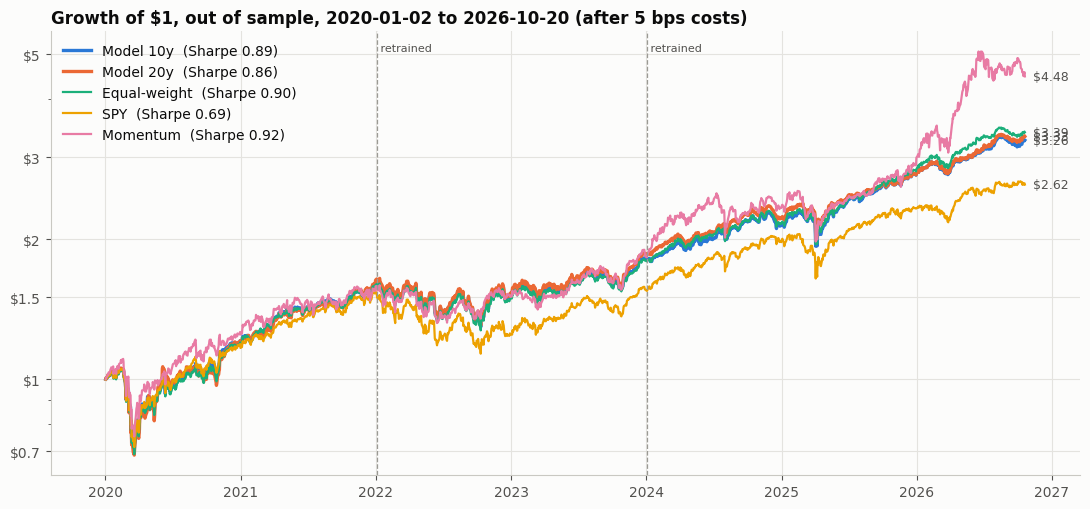

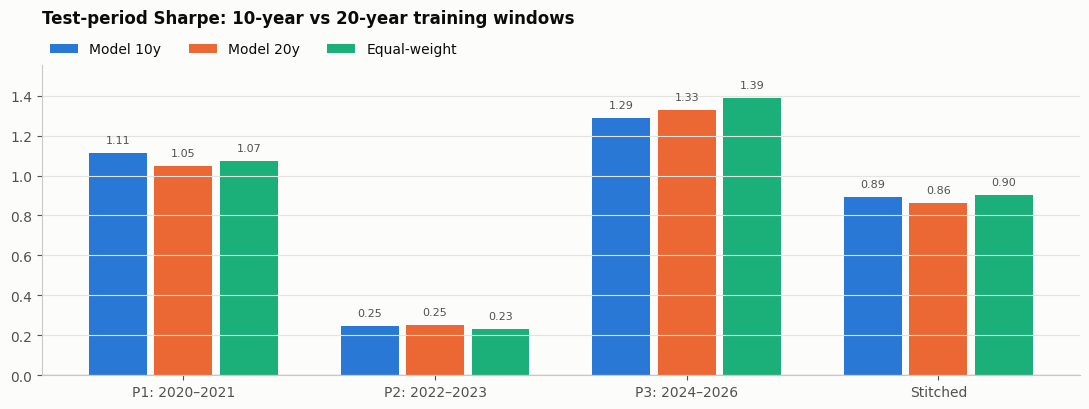

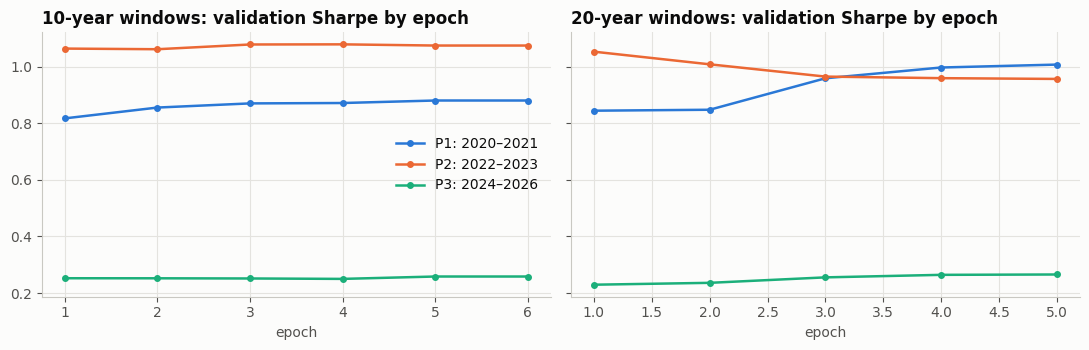

In [ ]:
t = time.time()
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
COLORS = {'Model 10y': '#2a78d6', 'Model 20y': '#eb6834', 'Equal-weight': '#1baf7a', 'SPY': '#eda100', 'Momentum': '#e87ba4'}
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'axes.edgecolor': '#c9c8c2',
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK, 'axes.titlecolor': INK,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': 0.8, 'legend.frameon': False, 'lines.linewidth': 1.8})

# 1. Equity curves
fig, ax = plt.subplots(figsize=(11, 5.2))
x = DATES[TEST_DAYS]
for k, bt in STITCHED.items():
    wealth = np.cumprod(1 + bt['net'])
    ax.plot(x, wealth, color=COLORS[k], lw=2.4 if k.startswith('Model') else 1.6, label=f'{k}  (Sharpe {SUMMARY.loc[k, "Sharpe"]:.2f})')
    ax.annotate(f'${wealth[-1]:.2f}', (x[-1], wealth[-1]), xytext=(6, 0), textcoords='offset points', va='center', fontsize=9, color=INK2)
for p in periods[1:]:
    b = DATES[next(r for r in RUNS.values() if r['period'] == p)['test_days'][0]]
    ax.axvline(b, color='#9b9a94', lw=0.9, ls='--'); ax.text(b, ax.get_ylim()[1], ' retrained', va='top', fontsize=8, color=INK2)
ax.set_yscale('log')
import matplotlib.ticker as mticker
ax.yaxis.set_major_locator(mticker.LogLocator(base=10, subs=(1.0, 1.5, 2.0, 3.0, 5.0, 7.0)))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.2g}'))
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_title(f'Growth of $1, out of sample, {x[0].date()} to {x[-1].date()} (after 5 bps costs)')
ax.legend(loc='upper left'); ax.margins(x=0.06)
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/equity_curves.png', dpi=150); plt.show()

# 2. Test Sharpe by period, 10y vs 20y vs equal-weight
labels = periods + ['Stitched']
vals = {k: [metrics(MODEL_BT[f'{p}_{k[6:]}'])['Sharpe'] for p in periods] + [SUMMARY.loc[k, 'Sharpe']] for k in ('Model 10y', 'Model 20y')}
vals['Equal-weight'] = [metrics(BENCH_BT[p]['Equal-weight'])['Sharpe'] for p in periods] + [SUMMARY.loc['Equal-weight', 'Sharpe']]
period_names = {f'P{i + 1}': f'P{i + 1}: {DATES[RUNS[f"P{i + 1}_10y"]["test_days"][0]].year}–{DATES[RUNS[f"P{i + 1}_10y"]["test_days"][-1]].year}' for i in range(len(periods))}
fig, ax = plt.subplots(figsize=(11, 4.2))
xs = np.arange(len(labels)); bw = 0.26
for j, (k, v) in enumerate(vals.items()):
    bars = ax.bar(xs + (j - 1) * bw, v, bw - 0.03, color=COLORS[k], label=k)
    for b_, val in zip(bars, v):
        ax.text(b_.get_x() + b_.get_width() / 2, val + (0.04 if val >= 0 else -0.04), f'{val:.2f}', ha='center',
                va='bottom' if val >= 0 else 'top', fontsize=8, color=INK2)
ax.axhline(0, color='#9b9a94', lw=0.9)
ax.set_xticks(xs, [period_names.get(l, l) for l in labels]); ax.grid(axis='x', visible=False)
ax.set_title('Test-period Sharpe: 10-year vs 20-year training windows', pad=30)
ax.legend(ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0), borderaxespad=0.2); ax.margins(y=0.12)
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/sharpe_by_period.png', dpi=150); plt.show()

# 3. Validation Sharpe per epoch
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
pcol = ['#2a78d6', '#eb6834', '#1baf7a']
for ax, Y in zip(axes, CFG['train_years']):
    for c, p in zip(pcol, periods):
        h = pd.DataFrame(RUNS[f'{p}_{Y}y']['hist'])
        ax.plot(h.epoch, h.val_sharpe, marker='o', ms=4, color=c, label=period_names[p])
    ax.set_title(f'{Y}-year windows: validation Sharpe by epoch'); ax.set_xlabel('epoch')
axes[0].legend(); fig.tight_layout(); fig.savefig(f'{FIG_DIR}/validation_curves.png', dpi=150); plt.show()
tick('Backtest, benchmarks, charts', t)

## Demo: tomorrow's 100 weights and what drove them

Uses the most recent test-period model (trained through 2023), picking the 10- or 20-year version by **validation** Sharpe so the choice doesn't peek at test results. Weights are for the open on the next trading day after the last date in the data. One forward pass picks all 100 weights in milliseconds.

Model P3_20y | features through the close on 2026-10-22 | one forward pass for 100 stocks: 11 ms
Effective holdings 93.7 | largest weight 1.20% | smallest 0.36%


,ticker,name,sector,weight,score
0,MNST,Monster Beverage,Consumer Staples,1.20%,+0.591
1,SBUX,Starbucks,Consumer Discretionary,1.20%,+0.590
2,RTX,RTX Corporation,Industrials,1.20%,+0.587
3,GD,General Dynamics,Industrials,1.20%,+0.586
4,PLD,Prologis,Real Estate,1.20%,+0.586
5,CVS,CVS Health,Health Care,1.20%,+0.585
6,PEP,PepsiCo,Consumer Staples,1.20%,+0.584
7,NEE,NextEra Energy,Utilities,1.20%,+0.584
8,GE,GE Aerospace,Industrials,1.19%,+0.583
9,MCD,McDonald's,Consumer Discretionary,1.19%,+0.579


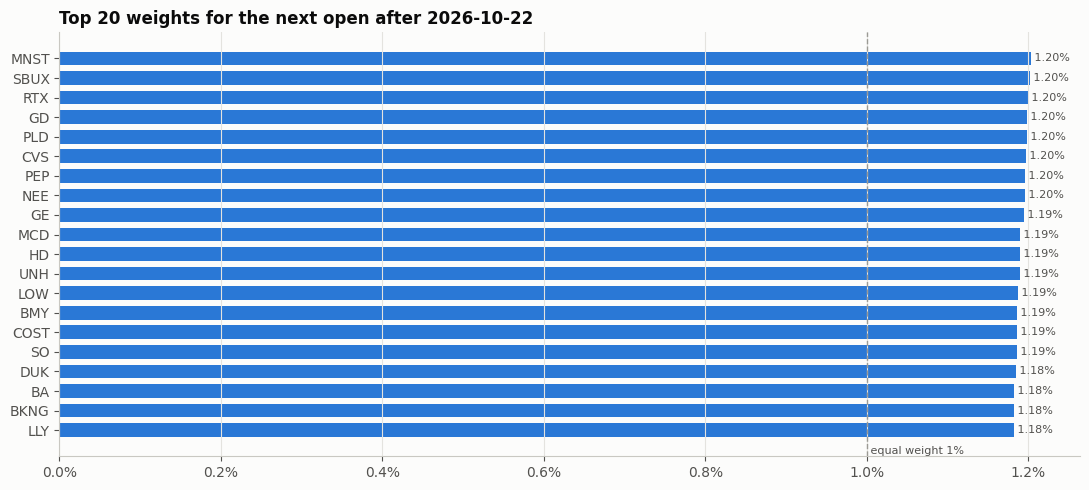

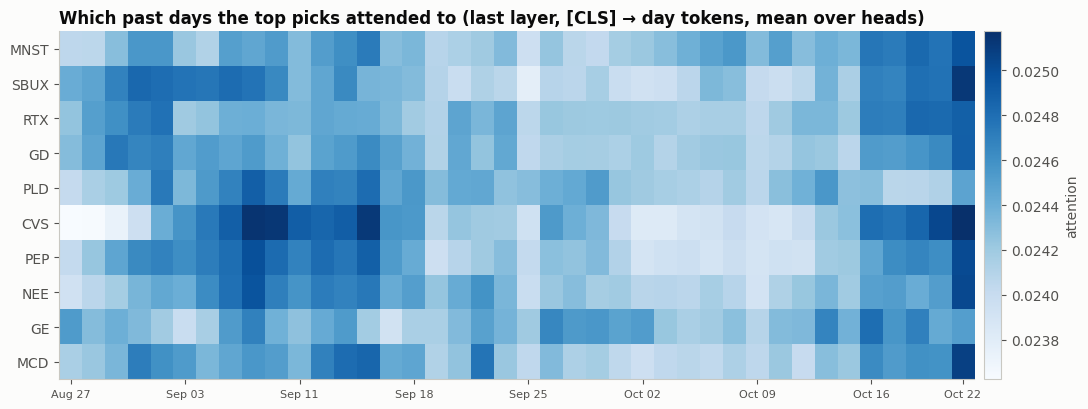

In [ ]:
t = time.time()
last_p = periods[-1]
pick = max(CFG['train_years'], key=lambda Y: RUNS[f'{last_p}_{Y}y']['info']['best_val_sharpe'])
R_ = RUNS[f'{last_p}_{pick}y']
demo = build_model(); demo.load_state_dict(R_['state_dict']); demo.eval()
XM_demo, _, _ = market_tensor(R_['train_days'])
day = T - 1
t_inf = time.time()
S_today = predict_scores(demo, np.array([day]), XM_demo)[0]
if DEVICE.type == 'cuda': torch.cuda.synchronize()
inf_ms = (time.time() - t_inf) * 1000
W_today = softmax_np(S_today[None])[0]
TOMORROW = universe[['ticker', 'name', 'sector']].assign(weight=W_today, score=S_today).sort_values('weight', ascending=False).reset_index(drop=True)
TOMORROW.to_csv(f'{RUN_DIR}/tomorrow_weights.csv', index=False)
print(f'Model {last_p}_{pick}y | features through the close on {DATES[day].date()} | one forward pass for 100 stocks: {inf_ms:.0f} ms')
print(f'Effective holdings {1 / np.sum(W_today ** 2):.1f} | largest weight {W_today.max():.2%} | smallest {W_today.min():.2%}')
display(TOMORROW.head(15).style.format({'weight': '{:.2%}', 'score': '{:+.3f}'}))

fig, ax = plt.subplots(figsize=(11, 5))
top = TOMORROW.head(20)[::-1]
ax.barh(top.ticker, top.weight, color='#2a78d6', height=0.7)
ax.axvline(1 / N, color='#9b9a94', ls='--', lw=1); ax.text(1 / N, -1.2, ' equal weight 1%', fontsize=8, color=INK2)
for yv, wv in enumerate(top.weight):
    ax.text(wv, yv, f' {wv:.2%}', va='center', fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.1%}')); ax.grid(axis='y', visible=False)
ax.set_title(f'Top 20 weights for the next open after {DATES[day].date()}')
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/tomorrow_weights.png', dpi=150); plt.show()

# Attention heat map: last layer, [CLS] row, averaged over heads, for the top 10 picks
top_idx = [TICKERS.index(tk) for tk in TOMORROW.ticker.head(10)]
with torch.no_grad():
    x, s = make_batch(torch.tensor([day], device=DEVICE), XM_demo)
    sel = torch.tensor(top_idx, device=DEVICE)
    _, attn = demo(x[sel].float(), s[sel], return_attn=True)
A = attn[-1][:, :, 0, 1:].mean(1).float().cpu().numpy()       # [10 stocks, 40 days]
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(A, aspect='auto', cmap='Blues')
lb_dates = DATES[day - LB + 1: day + 1]
ax.set_yticks(range(len(top_idx)), [TICKERS[i] for i in top_idx])
ticks = list(range(0, LB, 5)) + [LB - 1]
ax.set_xticks(ticks, [lb_dates[i].strftime('%b %d') for i in ticks], fontsize=8); ax.grid(False)
ax.set_title('Which past days the top picks attended to (last layer, [CLS] → day tokens, mean over heads)')
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01, label='attention')
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/attention_heatmap.png', dpi=150); plt.show()
tick('Backtest, benchmarks, charts', t)

## Runtime

In [ ]:
total = time.time() - T0
rt = pd.DataFrame({'minutes': {k: v / 60 for k, v in TIMINGS.items()}})
rt.loc['Total (whole notebook)'] = total / 60
display(rt.style.format('{:.1f}'))
for name, r in RUNS.items():
    h = pd.DataFrame(r['hist'])
    if len(h):
        print(f'{name}: {len(h)} epochs, {r["info"]["steps"]} steps, {h.epoch_sec.median():.0f}s per epoch, best val Sharpe {r["info"]["best_val_sharpe"]:.2f}')
print(f'\nGPU: {GPU_NAME} | model {N_PARAMS / 1e6:.2f}M parameters | TOTAL RUNTIME {total / 60:.1f} min '
      f'({"under" if total < 3600 else "OVER"} the 60-minute budget)')
print(f'Outputs in {RUN_DIR}: results_runs.csv, results_stitched.csv, tomorrow_weights.csv, figures/, runs/')

,minutes
Download and cache,1.9
Features,0.0
Overfit check,1.3
Training (6 runs),36.9
"Backtest, benchmarks, charts",0.1
Total (whole notebook),42.7


P1_10y: 6 epochs, 156 steps, 48s per epoch, best val Sharpe 0.88
P1_20y: 5 epochs, 324 steps, 99s per epoch, best val Sharpe 1.01
P2_10y: 6 epochs, 156 steps, 48s per epoch, best val Sharpe 1.08
P2_20y: 5 epochs, 325 steps, 105s per epoch, best val Sharpe 1.05
P3_10y: 6 epochs, 157 steps, 48s per epoch, best val Sharpe 0.26
P3_20y: 5 epochs, 323 steps, 106s per epoch, best val Sharpe 0.27

GPU: Tesla T4 | model 4.76M parameters | TOTAL RUNTIME 42.7 min (under the 60-minute budget)
Outputs in /content/sharpe-transformer: results_runs.csv, results_stitched.csv, tomorrow_weights.csv, figures/, runs/


## Caveats

- **Survivorship bias.** The universe is today's largest members that existed in 2000, so absolute returns are inflated. Lead with the gap over equal-weight, which carries the same bias.
- **Overfitting.** ~4.8M parameters against ~6,700 trading days and a noisy loss. Dropout, weight decay, early stopping and walk-forward testing limit it; averaging 3 seeds is the next step.
- **Execution.** Fills at the open with a flat cost and no taxes or market impact. The cost table shows 10 and 20 bps.
- **Real money.** A good backtest is not a live result. Paper-trade first. Not investment advice.

**Stretch items:** 3-seed averaging, the 5–20 year window study (Sharpe vs years of history), cross-stock attention over the 100 [CLS] outputs, and a Streamlit dashboard built from the CSVs and figures this notebook saves.

account for slipage
us actual 10 years t-bill for sharpe
shoot for 1 percent standard deviation
look at one day change and trade less
add borrow money at 8% annualized risk free rate of borrowing